## Use GridSearchCV for hyperparameter tuning of the best model by manually implementing an exhaustive search algorithm, evaluating multiple hyperparameter combinations without using built-in grid search methods.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LogisticRegression

df = pd.read_csv('heart.csv')                         
X, y = df.drop(columns='target').values.astype(float), df['target'].values
print(X.shape, '| positive share:', y.mean().round(2))

(303, 13) | positive share: 0.54


In [2]:
def auc(t, s):
    sp, sn = s[t == 1], s[t == 0]
    return (sp[:, None] > sn[None, :]).mean() + 0.5 * (sp[:, None] == sn[None, :]).mean()

def metrics(t, p):
    q = np.clip(p, 1e-6, 1 - 1e-6)
    return dict(acc=np.mean((p > 0.5) == t), auc=auc(t, p), logloss=-np.mean(t * np.log(q) + (1 - t) * np.log(1 - q)))

In [3]:
grid = {
    'C':            [0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10],
    'reg':          ['l1', 'l2'],
    'class_weight': ['none', 'balanced'],
    'fit_intercept':[True, False],
}
def expand_grid(g):
    combos = [{}]
    for key, values in g.items():
        combos = [{**c, key: v} for c in combos for v in values]      
    return combos

combos = expand_grid(grid)
print('Total combinations:', len(combos), '| pehle 2:', combos[:2])

def make_lr(p):                                       
    kw = dict(C=p['C'], class_weight=None if p['class_weight'] == 'none' else p['class_weight'], fit_intercept=p['fit_intercept'], solver='liblinear', max_iter=1000)
    if int(sklearn.__version__.split('.')[1]) >= 8 and sklearn.__version__.startswith('1.'): kw['l1_ratio'] = float(p['reg'] == 'l1')
    else: kw['penalty'] = p['reg']
    return LogisticRegression(**kw)

Total combinations: 64 | pehle 2: [{'C': 0.001, 'reg': 'l1', 'class_weight': 'none', 'fit_intercept': True}, {'C': 0.001, 'reg': 'l1', 'class_weight': 'none', 'fit_intercept': False}]


In [4]:
def make_folds(n, k, seed): return np.array_split(np.random.default_rng(seed).permutation(n), k)

def cv_score(p, A, t, seed, k=5):
    ms = []
    for f in make_folds(len(t), k, seed):
        tr = np.setdiff1d(np.arange(len(t)), f); mu, sd = A[tr].mean(0), A[tr].std(0)
        m = make_lr(p).fit((A[tr] - mu) / sd, t[tr])
        ms.append(metrics(t[f], m.predict_proba((A[f] - mu) / sd)[:, 1]))
    return {c: np.mean([m[c] for m in ms]) for c in ms[0]} | {'ll_se': np.std([m['logloss'] for m in ms], ddof=1) / np.sqrt(k)}

# 5. Exhaustive search: har combination try karo
def grid_search(A, t, seed):
    return [dict(**p, **cv_score(p, A, t, seed)) for p in combos]

In [5]:
results = pd.DataFrame(grid_search(X, y, seed=0)).sort_values('logloss').reset_index(drop=True)
print('Fits kiye:', len(combos) * 5, '(64 combos x 5 folds)')
results.head(10).round(4)

Fits kiye: 320 (64 combos x 5 folds)


,C,reg,class_weight,fit_intercept,acc,auc,logloss,ll_se
0,0.3,l2,none,False,0.8250,0.9120,0.3883,0.0265
1,0.3,l2,none,True,0.8251,0.9115,0.3896,0.0296
2,0.3,l2,balanced,False,0.8184,0.9104,0.3896,0.0255
3,0.1,l2,none,False,0.8217,0.9122,0.3899,0.0210
4,0.3,l2,balanced,True,0.8184,0.9107,0.3905,0.0257
5,0.1,l2,none,True,0.8152,0.9115,0.3905,0.0239
6,0.1,l2,balanced,False,0.8184,0.9113,0.3911,0.0203
7,0.1,l2,balanced,True,0.8184,0.9115,0.3916,0.0208
8,1.0,l2,none,False,0.8250,0.9114,0.3931,0.0310
9,1.0,l1,none,False,0.8284,0.9103,0.3938,0.0287


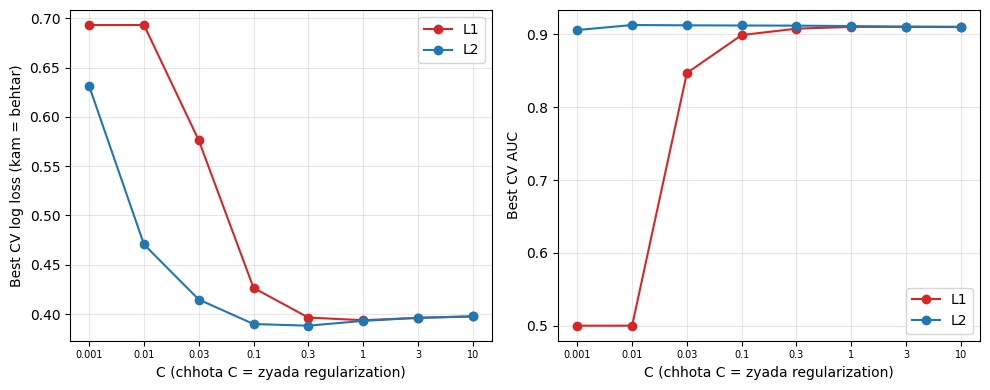

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col, fn, lab in [(axes[0], 'logloss', 'min', 'Best CV log loss (kam = behtar)'), (axes[1], 'auc', 'max', 'Best CV AUC')]:
    for reg, c in [('l1', 'tab:red'), ('l2', 'tab:blue')]:
        sub = results[results.reg == reg].groupby('C')[col].agg(fn)
        ax.plot(range(len(sub)), sub.values, 'o-', color=c, label=reg.upper())
    ax.set_xticks(range(len(grid['C']))); ax.set_xticklabels(grid['C'], fontsize=7); ax.set_xlabel('C (chhota C = zyada regularization)')
    ax.set_ylabel(lab); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [7]:
best = results.iloc[0]
within = results[results.logloss <= best.logloss + best.ll_se]
simple = within.sort_values(['C', 'fit_intercept'], ascending=[True, False]).iloc[0]
show = ['C', 'reg', 'class_weight', 'fit_intercept', 'logloss', 'auc', 'acc']
print('Best log loss:', best[show].to_dict())
print('1-SE (simple):', simple[show].to_dict(), '| candidates within 1 SE:', len(within))

Best log loss: {'C': 0.3, 'reg': 'l2', 'class_weight': 'none', 'fit_intercept': False, 'logloss': 0.38825790046758024, 'auc': 0.9120144020312029, 'acc': 0.8250273224043717}
1-SE (simple): {'C': 0.1, 'reg': 'l2', 'class_weight': 'none', 'fit_intercept': True, 'logloss': 0.3905490459676066, 'auc': 0.911522036760612, 'acc': 0.8151912568306011} | candidates within 1 SE: 36


In [8]:
default = dict(C=1, reg='l2', class_weight=None, fit_intercept=True)
nested = {'Default LR': [], 'Grid best': [], 'Grid 1-SE': []}
chosen = []
for rep in range(2):
    folds = make_folds(len(X), 5, 100 + rep)
    for k in range(5):
        te = folds[k]; tr = np.concatenate([folds[i] for i in range(5) if i != k])
        r = pd.DataFrame(grid_search(X[tr], y[tr], seed=rep * 5 + k)).sort_values('logloss')
        b = r.iloc[0]; s = r[r.logloss <= b.logloss + b.ll_se].sort_values(['C', 'fit_intercept'], ascending=[True, False]).iloc[0]
        chosen.append((b.C, b.reg, s.C, s.reg))
        mu, sd = X[tr].mean(0), X[tr].std(0); A, B = (X[tr] - mu) / sd, (X[te] - mu) / sd
        for name, p in [('Default LR', default), ('Grid best', b), ('Grid 1-SE', s)]:
            nested[name].append(metrics(y[te], make_lr(p).fit(A, y[tr]).predict_proba(B)[:, 1]))
base = np.array([m['acc'] for m in nested['Default LR']]); rows = []
for name, ms in nested.items():
    g = lambda c: np.array([m[c] for m in ms]); d = g('acc') - base
    rows.append((name, f"{g('acc').mean():.3f} +- {g('acc').std():.3f}", f"{g('auc').mean():.3f}", f"{g('logloss').mean():.3f}", f"{d.mean():+.3f} +- {d.std(ddof=1) / np.sqrt(len(d)):.3f}"))
print(pd.DataFrame(rows, columns=['Model', 'Accuracy', 'AUC', 'Log loss', 'Acc diff vs Default']).to_string())
print('\nOuter folds me chune gaye (best: C, reg | 1-SE: C, reg):'); print(pd.DataFrame(chosen, columns=['best C', 'best reg', '1SE C', '1SE reg']).value_counts().head(5).to_string())

        Model        Accuracy    AUC Log loss Acc diff vs Default
0  Default LR  0.822 +- 0.041  0.896    0.412     +0.000 +- 0.000
1   Grid best  0.822 +- 0.042  0.900    0.400     -0.000 +- 0.002
2   Grid 1-SE  0.822 +- 0.042  0.901    0.403     -0.000 +- 0.006

Outer folds me chune gaye (best: C, reg | 1-SE: C, reg):
best C  best reg  1SE C  1SE reg
0.1     l2        0.10   l2         6
                  0.03   l2         2
0.3     l2        0.03   l2         1
                  0.10   l2         1


In [9]:
mu, sd = X.mean(0), X.std(0)
final = make_lr(simple).fit((X - mu) / sd, y)
print('Final hyperparameters:', {k: simple[k] for k in grid})
print('Train accuracy (optimistic):', round(np.mean(final.predict((X - mu) / sd) == y), 3))

Final hyperparameters: {'C': np.float64(0.1), 'reg': 'l2', 'class_weight': 'none', 'fit_intercept': np.True_}
Train accuracy (optimistic): 0.842
